# Step 5.3: Wavelength Shift

Inference only. The Step 4 checkpoints are reloaded and never modified, and Step 5.0 has confirmed that the reload reproduces the clean baseline.

**The perturbation.** Every pixel of a spectrum is displaced by $\Delta x$ places along the grid, with the vacated edge filled by replicating the boundary value:

$$
f_{\text{shifted}}(\lambda_i) = f(\lambda_{i - \Delta x})
$$

On the logarithmic grid of Step 2 a uniform pixel shift is a constant-*velocity* displacement, identical at every wavelength, so this is a genuine radial-velocity offset rather than a wavelength-calibration artefact. This is the property the logarithmic grid was chosen for in Step 2, and it is what makes a single $\Delta x$ a physically meaningful quantity rather than a different perturbation at each end of the band.

**Four sweeps, because a pixel shift is not one operation.** The shared stem downsamples by exactly 32 (4096 input points to 128 tokens), so a displacement of $\Delta x$ pixels decomposes into two components that act on entirely different parts of the network:

$$
\Delta x = 32\,q + r, \qquad q = \lfloor \Delta x / 32 \rfloor, \quad r = \Delta x \bmod 32
$$

The remainder $r$ changes the sampling phase of the stride-2 convolutions and the max-pooling stages, which matters here because the Step 2 grid carries only 1.95 pixels per resolution element: after the first stride-2 convolution the stem is sampling *below* Nyquist for the line profiles, so a change of phase is not a small perturbation of the feature map but a different one. The quotient $q$ is an exact translation of the stem output by whole tokens, leaving the sampling phase untouched. Only $q$ reaches the positional encoding.

Sweep A varies $\Delta x$ continuously through the onset region and therefore mixes the two. Sweep B fixes $r = 0$ by using multiples of 32, isolating the token translation and with it the only component the fixed sinusoidal encoding of Conv-Attn can respond to. Conv-Pool should be close to immune there — its convolutions are translation-equivariant and its global average pooling is translation-invariant apart from the two tokens that enter and leave — so Sweep B is where the two architectures can be told apart.

**Why the whole-token sweep is reported separately.** Conv-Attn adds a fixed sinusoidal encoding to the feature map before the Transformer layers, tying each token to an absolute position, and that encoding is the one component of either model that is not translation-equivariant. A whole-token translation moves every diagnostic feature onto a token carrying a different positional signal from the one seen during training, while leaving Conv-Pool's equivariant body almost untouched. The encoding is therefore the natural candidate channel for any gap Sweep B opens. This notebook measures the gap and does not isolate the channel, which would require retraining with a learned or absent encoding.

**Sub-pixel displacements and the interpolation they require.** The physically relevant regime lies below one pixel: the grid carries 77.0 km/s per pixel, whereas SDSS wavelength calibration is accurate to a few km/s and the radial velocities of the sample are tens of km/s. Reaching that regime requires interpolation, and linear interpolation is not a pure displacement: the two-tap kernel $[1-f,\, f]$ that produces a fractional shift $f$ also attenuates, with a response at the Nyquist frequency of $|1-2f|$, so a half-pixel shift removes the Nyquist component entirely. On a grid sampling lines at 1.95 pixels per resolution element, that attenuation falls directly on the diagnostic features rather than on empty bandwidth, and left uncontrolled it would manufacture a spurious oscillation with maxima at half-integer shifts. Sweep C therefore applies the symmetric kernel $[f/2,\, 1-f,\, f/2]$, which has zero displacement and the same Nyquist response, so the smoothing component of a fractional shift can be separated from the displacement component. The two transfer functions agree exactly at DC and at Nyquist and only approximately in between, so Sweep C bounds the smoothing contribution rather than subtracting it exactly, and it over-attenuates at intermediate frequencies: at $\omega = \pi/2$ the symmetric kernel gives $1-f$ against $\sqrt{(1-f)^2 + f^2}$ for the interpolation.

Sweep D removes the confound at its source instead of bounding it, repeating the sub-pixel displacements through a phase ramp in the Fourier domain. That operation has unit magnitude response at every frequency, so it displaces without attenuating, and the comparison between Sweep A and Sweep D at equal displacement measures directly what the interpolation contributed.

**The collapse ceiling.** A model that has lost all input information predicts the sample mean, giving an RMSE equal to the standard deviation of the test labels, 962.9 K, and a degradation of about 882 K above the clean baseline. Degradations approaching that value do not measure robustness but the completeness of the collapse, and an architectural comparison there measures which model collapsed further. The ceiling is computed from the labels below and drawn on every figure so the boundary is visible rather than inferred, following the lesson of Step 5.1, where the Pool/Attn ratio fell from 3.59 to 1.61 at $k = 50$ for exactly this reason.

**In the paper.** The sub-pixel statement (Sweep A below one pixel, with Sweeps C and D as controls on the interpolation), the comparison of sampling phase against translation (Section 5.3.9), and the whole-token table (Sweep B). The directional-asymmetry and signed-bias analyses of Section 5.3.9 are additional and not reported in the paper. Per-spectrum predictions are written to disk, so any configuration can be re-analysed without re-running the attack.

## 5.3.1 Configuration

Three sweeps. Sweep A covers the shift magnitude in both directions, with sub-pixel spacing through the onset and integer levels continuing into the collapsed regime. Sweep B covers whole-token translations, multiples of the stem downsampling factor, in both directions. Sweep C is the smoothing control and has no direction, since the symmetric kernel displaces nothing.

The shift is deterministic given $\Delta x$: there is no random position to draw, so every spectrum receives the identical displacement and there is no draw-to-draw variance of the kind checked in Step 5.1. As in Step 5.1 and 5.2, every model and seed sees the **identical** perturbed tensor at each level: the tensor is built once and pushed through all ten networks before the next one is generated.

In [1]:
import os
import json
import time
import math

import numpy as np
import pandas as pd
import h5py
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# CONFIGURATION
# ==========================================
DATA_DIR    = 'data'
RESULTS_DIR = 'results'
CKPT_DIR    = 'checkpoints'
STEP53_DIR  = os.path.join(RESULTS_DIR, 'step53')

MODELS = ['Conv-Pool', 'Conv-Attn']
SEEDS  = [0, 1, 2, 3, 4]

BATCH_SIZE = 256

# ---- attack ------------------------------------------------------------------
ATTACK      = 'wavelength_shift'
ATTACK_SEED = 53          # the perturbation is deterministic and consumes no random
                          # stream; recorded for convention and for any extension

STEM_DOWNSAMPLE = 32      # 4096 input points -> 128 tokens; asserted below

# sweep A: shift magnitude, both directions. Sub-pixel through the onset, integer
# levels continuing into the collapsed regime.
DX_LEVELS    = [0.25, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 5, 8, 12, 20, 35]

# sweep B: whole-token translation, sampling phase unchanged, both directions
TOKEN_LEVELS = [32, 64, 96]

# sweep C: smoothing control, matched to the Nyquist response of the fractional
# shifts of sweep A, no direction
SMOOTH_LEVELS = [0.25, 0.5, 0.75]

# sweep D: the sub-pixel levels repeated with a Fourier shift, whose magnitude
# response is unity at every frequency except the single Nyquist bin
FOURIER_LEVELS = [0.25, 0.5, 0.75]
FOURIER_PAD    = 256      # edge-replicated padding, cropped after the transform

DIRECTIONS  = ['redshift', 'blueshift']       # +dx, -dx respectively

CATASTROPHIC_K = 300.0    # same convention as Step 5.0, 5.1 and 5.2

# metrics carried through from Step 5.0; the clean value of each is subtracted
# from its attacked counterpart within the same model and seed
METRIC_COLS = ['rmse_K', 'mae_K', 'bias_K', 'p99_abs_K', 'gross_fail_frac']

COLORS = {'Conv-Pool': '#0173B2', 'Conv-Attn': '#DE8F05'}
DIR_SIGN = {'redshift': +1, 'blueshift': -1}
DIR_STYLE = {'redshift': '-', 'blueshift': '--'}

# ==========================================
# PLOT STYLE
# ==========================================
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 130,
})

W_DOUBLE = 7.0

# ==========================================
# LOAD METADATA AND THE STEP 5.0 BASELINE
# ==========================================
import common
device = common.get_device()

os.makedirs(STEP53_DIR, exist_ok=True)

with open(os.path.join(DATA_DIR, 'preprocessing_meta.json')) as f:
    prep = json.load(f)
with open(os.path.join(RESULTS_DIR, 'step50_meta.json')) as f:
    meta50 = json.load(f)

TEFF_MIN    = prep['teff_min']
TEFF_RANGE  = prep['teff_range']
NOISE_FLOOR = meta50['label_noise_floor_K']
GRID        = prep['grid']
GRID_N      = GRID['seq_length']
REG_EDGES   = meta50['regime_edges_K']

assert meta50['gate_passed'], 'Step 5.0 integrity gate did not pass'
assert meta50['eval_batch_size'] == BATCH_SIZE, 'batch size differs from Step 5.0'
assert max(DX_LEVELS + TOKEN_LEVELS) < GRID_N, 'a shift cannot exceed the vector length'
assert all(t % STEM_DOWNSAMPLE == 0 for t in TOKEN_LEVELS), \
    'sweep B levels must be exact multiples of the stem downsampling factor'
assert all(0.0 < f < 1.0 for f in SMOOTH_LEVELS), 'smoothing levels are fractions'
assert all(l in DX_LEVELS for l in FOURIER_LEVELS), \
    'every Fourier level must have a linear-interpolation counterpart in sweep A'

clean_metrics = pd.read_csv(os.path.join(RESULTS_DIR, 'step50_baseline_metrics.csv'))

n_cfg = (len(DX_LEVELS) + len(TOKEN_LEVELS) + len(FOURIER_LEVELS)) * len(DIRECTIONS) \
        + len(SMOOTH_LEVELS)
print(f'Device      : {device}')
print(f'Sweep A     : |dx| in {DX_LEVELS} px, both directions')
print(f'Sweep B     : |dx| in {TOKEN_LEVELS} px (multiples of {STEM_DOWNSAMPLE}), '
      f'both directions')
print(f'Sweep C     : smoothing f in {SMOOTH_LEVELS}, no direction')
print(f'Sweep D     : Fourier shift |dx| in {FOURIER_LEVELS} px, both directions')
print(f'{n_cfg} configurations, {n_cfg * len(SEEDS) * len(MODELS)} forward passes')

Device      : cpu
Sweep A     : |dx| in [0.25, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 5, 8, 12, 20, 35] px, both directions
Sweep B     : |dx| in [32, 64, 96] px (multiples of 32), both directions
Sweep C     : smoothing f in [0.25, 0.5, 0.75], no direction
Sweep D     : Fourier shift |dx| in [0.25, 0.5, 0.75] px, both directions
41 configurations, 410 forward passes


## 5.3.2 Architectures

The two models are defined once, in `models.py`, and loaded through `common.py` exactly as in Step 5.0. The parity check halts the notebook if a definition has drifted from the one the checkpoints were written against. The stem downsampling factor, on which Sweep B is built, is asserted against the network as well.

In [2]:
from models import SharedStem, check_parameter_parity
import common

check_parameter_parity()


def load_model(model_name, seed):
    return common.load_model(model_name, seed, device, CKPT_DIR)


def predict(model, x, batch_size=BATCH_SIZE):
    """Forward a device-resident tensor; returns absolute temperatures in Kelvin."""
    return common.predict(model, x, TEFF_MIN, TEFF_RANGE, batch_size)


def metrics(pred_k, true_k):
    return common.metrics(pred_k, true_k, CATASTROPHIC_K)


# the stem downsampling factor is asserted against the network rather than assumed,
# since sweep B is defined by it
with torch.no_grad():
    _seq = SharedStem()(torch.zeros(1, 1, GRID_N)).shape[-1]
assert GRID_N // _seq == STEM_DOWNSAMPLE, \
    f'stem downsamples by {GRID_N // _seq}, not {STEM_DOWNSAMPLE}'
print(f'Stem: {GRID_N} points -> {_seq} tokens, factor {STEM_DOWNSAMPLE}')
del _seq

Conv-Pool : 537,857 parameters
Conv-Attn : 540,161 parameters
difference: 2,304 (0.43%)
Stem: 4096 points -> 128 tokens, factor 32


## 5.3.3 Test partition, wavelength grid and the collapse ceiling

Loaded exactly as in Step 4a, 5.0, 5.1 and 5.2. The clean tensor stays resident on the device throughout; every perturbed tensor is a fresh copy derived from it.

The collapse ceiling is the RMSE of the best constant predictor, which is the standard deviation of the test labels. It is the value a model reaches once the input carries no usable information, and it bounds every degradation reported below.

In [3]:
test_idx, X_test, y_true_k = common.load_test_split(DATA_DIR, GRID_N)
N_TEST = len(test_idx)
X_clean = torch.from_numpy(X_test).to(device)

regime = pd.cut(y_true_k, bins=REG_EDGES)
REG_LABELS = [str(c) for c in regime.categories]
regime_mask = {str(c): np.asarray(regime == c) for c in regime.categories}

assert not np.isnan(X_test).any(), 'NaN in the test tensor'

# --- collapse ceiling ---------------------------------------------------------
COLLAPSE_RMSE = float(np.std(y_true_k))
CEILING = {m: COLLAPSE_RMSE - float(
    clean_metrics[(clean_metrics.model == m) &
                  (clean_metrics.regime == 'all')]['rmse_K'].mean())
    for m in MODELS}
CEILING_MEAN = float(np.mean(list(CEILING.values())))

# --- wavelength grid ----------------------------------------------------------
GRID_LO, GRID_HI = GRID['wave_start'], GRID['wave_end']
DLOG10 = GRID['dlog10']
KMS_PER_PIXEL = GRID['km_s_per_pixel']
wavegrid = GRID_LO * (GRID_HI / GRID_LO) ** (np.arange(GRID_N) / (GRID_N - 1))
pixel_axis = np.arange(GRID_N)

def lam_to_pixel(lam):
    return float(np.interp(lam, wavegrid, pixel_axis))

LINES = {'Ca II K': 3933.7, 'H-delta': 4101.7, 'H-gamma': 4340.5, 'H-beta': 4861.3,
         'Mg b': 5175.0, 'Na D': 5893.0, 'H-alpha': 6562.8, 'TiO bandhead': 7055.0,
         'Ca II 8542': 8542.1}

print(f'test spectra    : {N_TEST:,}')
print(f'grid            : {GRID_LO:.0f}-{GRID_HI:.0f} A, {GRID_N} points, '
      f'{KMS_PER_PIXEL:.2f} km/s per pixel')
print(f'collapse RMSE   : {COLLAPSE_RMSE:.1f} K  (best constant predictor)')
print(f'ceiling on dRMSE: ' + ', '.join(f'{m} {CEILING[m]:.1f} K' for m in MODELS))
print()
print('sweep A magnitudes in physical units — constant at every wavelength, by')
print('construction of the logarithmic grid:')
for dx in DX_LEVELS:
    print(f'  |dx| = {dx:5.2f} px = {dx * KMS_PER_PIXEL:7.1f} km/s')
print()
print('sweep B magnitudes, whole-token translations:')
for dx in TOKEN_LEVELS:
    print(f'  |dx| = {dx:5d} px = {dx * KMS_PER_PIXEL:7.1f} km/s = '
          f'{dx // STEM_DOWNSAMPLE} token(s), sampling phase unchanged')
print()
print(f'The instrumental resolution element is about 150 km/s at R ~ 2000, that is')
print(f'{150 / KMS_PER_PIXEL:.2f} px. SDSS wavelength calibration is accurate to a few')
print(f'km/s and the radial velocities of the sample are tens of km/s, so the')
print(f'physically relevant regime is the sub-pixel part of sweep A.')

test spectra    : 18,898
grid            : 3600-10300 A, 4096 points, 76.96 km/s per pixel
collapse RMSE   : 962.9 K  (best constant predictor)
ceiling on dRMSE: Conv-Pool 881.9 K, Conv-Attn 881.2 K

sweep A magnitudes in physical units — constant at every wavelength, by
construction of the logarithmic grid:
  |dx| =  0.25 px =    19.2 km/s
  |dx| =  0.50 px =    38.5 km/s
  |dx| =  0.75 px =    57.7 km/s
  |dx| =  1.00 px =    77.0 km/s
  |dx| =  1.50 px =   115.4 km/s
  |dx| =  2.00 px =   153.9 km/s
  |dx| =  2.50 px =   192.4 km/s
  |dx| =  3.00 px =   230.9 km/s
  |dx| =  5.00 px =   384.8 km/s
  |dx| =  8.00 px =   615.7 km/s
  |dx| = 12.00 px =   923.5 km/s
  |dx| = 20.00 px =  1539.2 km/s
  |dx| = 35.00 px =  2693.5 km/s

sweep B magnitudes, whole-token translations:
  |dx| =    32 px =  2462.7 km/s = 1 token(s), sampling phase unchanged
  |dx| =    64 px =  4925.3 km/s = 2 token(s), sampling phase unchanged
  |dx| =    96 px =  7388.0 km/s = 3 token(s), sampling phase unchange

## 5.3.4 The perturbations

**Integer shift.** Displacement by whole pixels, with the vacated edge replicated from the boundary value. The fill convention matches what Step 2 already does at the blue edge, where the resampling extends the first usable value across the 59 unusable pixels, so the models have encountered a constant edge segment in every training spectrum and the fill is not itself an out-of-distribution event.

**Fractional shift.** For $\Delta x = n + f$ with $n = \lfloor \Delta x \rfloor$ and $0 < f < 1$, linear interpolation between the two bracketing integer shifts:

$$
f_{\text{shifted}}[i] = (1-f)\, x[i-n] + f\, x[i-n-1]
$$

Linear interpolation is used rather than a higher-order or Fourier scheme because it is what the Step 2 resampler itself applies, and because cubic interpolants overshoot at the cores of narrow absorption lines and would synthesise structure the models could read as a feature. The floor convention makes the expression correct for negative $\Delta x$ as well.

**Smoothing control.** The symmetric kernel $[f/2,\, 1-f,\, f/2]$, which displaces nothing and matches the Nyquist response $1-2f$ of the interpolation kernel above. Its purpose is stated in the introduction: without it, the attenuation that necessarily accompanies a fractional shift is indistinguishable from the shift itself, and would appear as an oscillation peaking at half-integer displacements. The magnitude response of the two-tap kernel is invariant under $f \leftrightarrow 1-f$, so a control at $f$ serves the shifts of $+f$ and $-f$ alike and the comparison between the two directions at equal $|\Delta x|$ carries no smoothing difference at all.

**Fourier shift.** The sub-pixel levels are additionally displaced by multiplying the discrete transform by a phase ramp, which is an exact translation for a band-limited signal and has unit magnitude response at every frequency: it removes the attenuation rather than bounding it. Two properties of the implementation are recorded because they are the only places where it is not exact. The transform assumes periodicity, so the vector is padded by 256 edge-replicated pixels before the transform and cropped afterwards, confining the wrap-around discontinuity to the padding. And the Nyquist bin of a real transform is real and cannot carry phase, so it is set to zero rather than being rotated into a spurious amplitude change; this removes one bin of 2305 instead of applying the broadband rolloff that linear interpolation applies. The practical size of that difference is printed below at the frequency where it matters, the resolution element of 1.95 pixels.

Each routine is checked below against signals whose exact response is known — a linear ramp, which a symmetric kernel must preserve exactly, and the Nyquist-frequency alternating sequence, whose attenuation is $1-2f$ by construction — so that a sign error, an off-by-one, or a mismatched kernel fails here rather than producing a plausible curve later.

In [4]:
def _shift_int(x, n):
    """Integer shift by n pixels with edge replication. x is left untouched.

    n > 0 : redshift.  Content moves to higher pixel index; the first n pixels
            of the output repeat the original left-edge value.
    n < 0 : blueshift.  Content moves to lower pixel index; the last |n| pixels
            of the output repeat the original right-edge value."""
    if n == 0:
        return x.clone()
    L = x.shape[-1]
    out = torch.empty_like(x)
    if n > 0:
        out[:, :, n:] = x[:, :, :L - n]
        out[:, :, :n] = x[:, :, :1]
    else:
        d = -n
        out[:, :, :L - d] = x[:, :, d:]
        out[:, :, L - d:] = x[:, :, -1:]
    return out


def shift(x, dx):
    """Displace by dx pixels; dx may be fractional.

    A fractional dx is linear interpolation between the two bracketing integer
    shifts, which is a two-tap kernel [1-f, f]: it displaces by f and attenuates
    the Nyquist component by |1-2f|.  Sweep C measures that second effect."""
    n = math.floor(dx)
    f = float(dx) - n
    if f < 1e-12:
        return _shift_int(x, int(n))
    out = _shift_int(x, int(n))
    out.mul_(1.0 - f)
    tmp = _shift_int(x, int(n) + 1)
    out.add_(tmp, alpha=f)
    del tmp
    return out


def smooth(x, f):
    """Symmetric three-tap kernel [f/2, 1-f, f/2]: zero displacement, Nyquist
    response 1 - 2f, matching the fractional shift of the same f."""
    out = x * (1.0 - f)
    out.add_(_shift_int(x, 1), alpha=f / 2.0)
    out.add_(_shift_int(x, -1), alpha=f / 2.0)
    return out


def shift_fourier(x, dx, pad=FOURIER_PAD, chunk=4096):
    """Displace by dx pixels through a phase ramp in the Fourier domain.

    Unlike linear interpolation this has unit magnitude response at every
    frequency, so it carries no smoothing.  Two caveats, both handled here:
    the transform assumes periodicity, so the vector is padded with replicated
    edge values and cropped afterwards; and the Nyquist bin of a real transform
    cannot carry phase, so it is zeroed rather than rotated."""
    L = x.shape[-1]
    outs = []
    for i in range(0, x.shape[0], chunk):
        xb = x[i:i + chunk]
        left = xb[:, :, :1].expand(-1, -1, pad)
        right = xb[:, :, -1:].expand(-1, -1, pad)
        xp = torch.cat([left, xb, right], dim=-1)
        N = xp.shape[-1]
        X = torch.fft.rfft(xp, dim=-1)
        k = torch.arange(X.shape[-1], dtype=torch.float32, device=x.device)
        ramp = torch.exp(torch.complex(torch.zeros_like(k),
                                       -2.0 * math.pi * k * float(dx) / N))
        X = X * ramp
        if N % 2 == 0:
            X[..., -1] = 0
        o = torch.fft.irfft(X, n=N, dim=-1)
        outs.append(o[:, :, pad:pad + L])
        del xp, X, o
    return torch.cat(outs, dim=0).to(x.dtype)


def run_tensor(x_att):
    """Evaluate all ten networks on one perturbed tensor."""
    out = np.empty((len(SEEDS), len(MODELS), N_TEST), dtype=np.float32)
    for si, seed in enumerate(SEEDS):
        for mi, m in enumerate(MODELS):
            model = load_model(m, seed)
            out[si, mi] = predict(model, x_att).astype(np.float32)
            del model
            if device.type == 'cuda':
                torch.cuda.empty_cache()
    return out


def path_dx(dx):
    """Integer levels keep the plain three-digit form, so files already on disk
    from an earlier grid are reused rather than recomputed."""
    s = 'p' if dx >= 0 else 'm'
    a = abs(float(dx))
    if float(a).is_integer():
        return os.path.join(STEP53_DIR, f'preds_dx{s}{int(a):03d}.npz')
    cents = int(round((a - int(a)) * 100))
    return os.path.join(STEP53_DIR, f'preds_dx{s}{int(a):03d}p{cents:02d}.npz')


def path_smooth(f):
    return os.path.join(STEP53_DIR, f'preds_smooth{int(round(f * 100)):02d}.npz')


PATH_FNULL = os.path.join(STEP53_DIR, 'preds_fourier_null.npz')
PATH_CLEAN = os.path.join(STEP53_DIR, 'preds_clean.npz')


def path_fdx(dx):
    s_ = 'p' if dx >= 0 else 'm'
    a = abs(float(dx))
    cents = int(round((a - int(a)) * 100))
    return os.path.join(STEP53_DIR, f'preds_fdx{s_}{int(a):03d}p{cents:02d}.npz')


# --- verification -------------------------------------------------------------
_ref = torch.arange(GRID_N, dtype=torch.float32, device=device).repeat(4, 1).unsqueeze(1)
_ramp = _ref.clone()
_nyq = torch.tensor([(-1.0) ** i for i in range(GRID_N)],
                    dtype=torch.float32, device=device).repeat(4, 1).unsqueeze(1)

# integer shift: exact translation in the interior, edge replicated
_r = _shift_int(_ramp, 5)
assert torch.equal(_r[:, :, 5:], _ramp[:, :, :-5]), 'redshift interior is not a translation'
assert torch.all(_r[:, :, :5] == 0.0), 'redshift edge fill is not the left-edge value'
_b = _shift_int(_ramp, -5)
assert torch.equal(_b[:, :, :-5], _ramp[:, :, 5:]), 'blueshift interior is not a translation'
assert torch.all(_b[:, :, -5:] == GRID_N - 1), 'blueshift edge fill is not the right-edge value'
assert torch.equal(_shift_int(_ramp, 0), _ramp), 'n = 0 is not a no-op'

# fractional shift: an integer argument must take the integer path exactly
for _n in (-3, -1, 0, 1, 3):
    assert torch.equal(shift(_ramp, float(_n)), _shift_int(_ramp, _n)), \
        f'fractional path disagrees with the integer path at dx = {_n}'

# fractional shift of a ramp displaces it by exactly dx in the interior
for _dx in (0.25, 0.5, 2.5, -0.75, -1.5):
    _o = shift(_ramp, _dx)
    _lo, _hi = 40, GRID_N - 40
    assert torch.allclose(_o[:, :, _lo:_hi], _ramp[:, :, _lo:_hi] - _dx, atol=1e-3), \
        f'fractional shift of a ramp is not a displacement by {_dx}'

# smoothing control: preserves a ramp exactly, attenuates Nyquist by 1 - 2f
for _f in SMOOTH_LEVELS:
    _o = smooth(_ramp, _f)
    assert torch.allclose(_o[:, :, 40:-40], _ramp[:, :, 40:-40], atol=1e-3), \
        f'smoothing control displaces a ramp at f = {_f}'
    _got = float(smooth(_nyq, _f)[0, 0, GRID_N // 2] / _nyq[0, 0, GRID_N // 2])
    assert abs(_got - (1 - 2 * _f)) < 1e-5, \
        f'smoothing Nyquist response {_got:.4f} != {1 - 2 * _f:.4f} at f = {_f}'
    _gots = float(shift(_nyq, _f)[0, 0, GRID_N // 2] / _nyq[0, 0, GRID_N // 2])
    assert abs(abs(_gots) - abs(1 - 2 * _f)) < 1e-5, \
        f'shift Nyquist response does not match the control at f = {_f}'

# Fourier shift: exact on a band-limited signal, amplitude preserved where linear
# interpolation attenuates most
_t = torch.arange(GRID_N, dtype=torch.float32, device=device)
_sine = torch.sin(2 * math.pi * _t / 64.0).reshape(1, 1, GRID_N)
for _dx in (0.25, 0.5, -0.75):
    _o = shift_fourier(_sine, _dx)
    _e = torch.sin(2 * math.pi * (_t - _dx) / 64.0).reshape(1, 1, GRID_N)
    assert torch.allclose(_o[:, :, 200:-200], _e[:, :, 200:-200], atol=2e-3), \
        f'Fourier shift is not exact on a band-limited signal at dx = {_dx}'
_o = shift_fourier(_sine, 1.0)
assert torch.allclose(_o[:, :, 200:-200], _shift_int(_sine, 1)[:, :, 200:-200],
                      atol=2e-3), 'Fourier shift disagrees with the integer shift'
_rt = shift_fourier(shift_fourier(_sine, 0.5), -0.5)
assert torch.allclose(_rt[:, :, 200:-200], _sine[:, :, 200:-200], atol=2e-3), \
    'Fourier shift does not round-trip'

# the amplitude comparison, at two scales that must not be confused. A resolution
# element spans 1.95 px, so a *resolved* line oscillates with a period of about
# twice that; a sinusoid whose period equals 1.95 px sits at the sampling limit
# instead, where the interpolation kernel nulls completely at f = 0.5.
_RES_PX = 150.0 / KMS_PER_PIXEL
_amp = {}
for _lab, _per in (('a resolved line', 2.0 * _RES_PX),
                   ('the sampling limit', _RES_PX)):
    _w = torch.sin(2 * math.pi * _t / _per).reshape(1, 1, GRID_N)
    _amp[_lab] = (float(shift(_w, 0.5)[:, :, 200:-200].abs().max()),
                  float(shift_fourier(_w, 0.5)[:, :, 200:-200].abs().max()), _per)
    del _w

assert torch.equal(_ramp, _ref), 'the input tensor was modified in place'

print('verified against a linear ramp and the Nyquist sequence:')
print('  integer shift   : interior translation exact both directions, edges replicated')
print('  fractional shift: integer arguments take the integer path; a ramp is displaced')
print('                    by exactly dx')
print('  smoothing       : a ramp is preserved (zero displacement), and the Nyquist')
print('                    response matches |1 - 2f| of the shift kernel:')
for _f in SMOOTH_LEVELS:
    print(f'                      f = {_f:.2f} -> {1 - 2 * _f:+.2f}')
print('  Fourier shift  : exact on a band-limited signal, agrees with the integer')
print('                   shift, and round-trips')
print('  amplitude retained by a sinusoid displaced 0.5 px (1.0 if unperturbed):')
for _lab, (_al, _af, _per) in _amp.items():
    print(f'    {_lab:20s} period {_per:5.2f} px : linear {_al:.4f}, Fourier {_af:.4f}')
print('  the first is the scale of a resolved line and is the representative figure;')
print('  the second is the highest frequency the grid can carry, where the two-tap')
print('  kernel nulls entirely — the extreme case, not the typical one')
print('  input tensor untouched by every routine')
del _ref, _ramp, _nyq, _r, _b, _o, _n, _dx, _f, _got, _gots
del _t, _sine, _e, _rt, _RES_PX, _amp, _lab, _per, _al, _af

verified against a linear ramp and the Nyquist sequence:
  integer shift   : interior translation exact both directions, edges replicated
  fractional shift: integer arguments take the integer path; a ramp is displaced
                    by exactly dx
  smoothing       : a ramp is preserved (zero displacement), and the Nyquist
                    response matches |1 - 2f| of the shift kernel:
                      f = 0.25 -> +0.50
                      f = 0.50 -> +0.00
                      f = 0.75 -> -0.50
  Fourier shift  : exact on a band-limited signal, agrees with the integer
                   shift, and round-trips
  amplitude retained by a sinusoid displaced 0.5 px (1.0 if unperturbed):
    a resolved line      period  3.90 px : linear 0.6925, Fourier 1.0003
    the sampling limit   period  1.95 px : linear 0.0413, Fourier 1.0185
  the first is the scale of a resolved line and is the representative figure;
  the second is the highest frequency the grid can carry, where the 

## 5.3.5 Sweep A — shift magnitude

Both directions on the full test partition, so the degradations are directly comparable with Step 5.1 and 5.2. Results are written per level, so an interrupted run resumes rather than restarting, and levels already on disk from an earlier grid are reused.

In [5]:
_m = load_model(MODELS[0], SEEDS[0])
_t0 = time.time(); predict(_m, X_clean); _t = time.time() - _t0
del _m
if device.type == 'cuda':
    torch.cuda.empty_cache()

todo = sum(1 for d in DIRECTIONS for mag in DX_LEVELS
           if not os.path.exists(path_dx(DIR_SIGN[d] * mag)))
todo += sum(1 for d in DIRECTIONS for mag in TOKEN_LEVELS
            if not os.path.exists(path_dx(DIR_SIGN[d] * mag)))
todo += sum(1 for f in SMOOTH_LEVELS if not os.path.exists(path_smooth(f)))
todo += sum(1 for d in DIRECTIONS for mag in FOURIER_LEVELS
            if not os.path.exists(path_fdx(DIR_SIGN[d] * mag)))
todo += 0 if os.path.exists(PATH_FNULL) else 1
todo += 0 if os.path.exists(PATH_CLEAN) else 1

print(f'one forward pass  : {_t:.1f} s')
print(f'tensors to run    : {todo}  ({todo * len(SEEDS) * len(MODELS)} forward passes)')
print(f'projected total   : {_t * todo * len(SEEDS) * len(MODELS) * 1.4 / 60:.0f} min')
print('Configurations already on disk are skipped.')

one forward pass  : 14.3 s
tensors to run    : 43  (430 forward passes)
projected total   : 144 min
Configurations already on disk are skipped.


In [6]:
def run_shift_levels(levels, label):
    for direction in DIRECTIONS:
        sign = DIR_SIGN[direction]
        for mag in levels:
            dx = sign * mag
            if os.path.exists(path_dx(dx)):
                print(f'[skip] {label} {direction:9s} |dx| = {mag:6.2f}')
                continue
            t0 = time.time()
            X_att = shift(X_clean, dx)
            preds = run_tensor(X_att)
            del X_att
            np.savez_compressed(path_dx(dx), preds=preds, dx=float(dx),
                                direction=direction, sweep=label,
                                seeds=np.array(SEEDS), models=np.array(MODELS),
                                attack_seed=ATTACK_SEED)
            rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
            print(f'{label} {direction:9s} dx = {dx:+7.2f}   ' + '   '.join(
                f'{m} {rmse[:, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
                + f'   ({time.time() - t0:.0f}s)')


run_shift_levels(DX_LEVELS, 'A')

A redshift  dx =   +0.25   Conv-Pool   81.81 K   Conv-Attn   82.90 K   (197s)
A redshift  dx =   +0.50   Conv-Pool   86.58 K   Conv-Attn   87.46 K   (216s)
A redshift  dx =   +0.75   Conv-Pool   97.38 K   Conv-Attn   95.19 K   (190s)
A redshift  dx =   +1.00   Conv-Pool  117.23 K   Conv-Attn  106.71 K   (195s)
A redshift  dx =   +1.50   Conv-Pool  165.52 K   Conv-Attn  136.45 K   (218s)
A redshift  dx =   +2.00   Conv-Pool  294.49 K   Conv-Attn  192.89 K   (215s)
A redshift  dx =   +2.50   Conv-Pool  488.29 K   Conv-Attn  270.04 K   (216s)
A redshift  dx =   +3.00   Conv-Pool  658.35 K   Conv-Attn  356.70 K   (215s)
A redshift  dx =   +5.00   Conv-Pool  939.55 K   Conv-Attn  497.22 K   (212s)
A redshift  dx =   +8.00   Conv-Pool  668.83 K   Conv-Attn  345.71 K   (214s)
A redshift  dx =  +12.00   Conv-Pool  683.50 K   Conv-Attn  621.43 K   (220s)
A redshift  dx =  +20.00   Conv-Pool  897.02 K   Conv-Attn  593.94 K   (223s)
A redshift  dx =  +35.00   Conv-Pool  664.92 K   Conv-Attn  386.

## 5.3.6 Sweep B — whole-token translation

Multiples of the stem downsampling factor, so the sampling phase of the stride-2 convolutions and the max-pooling stages is identical to the clean input and the stem output is translated by exactly $\Delta x / 32$ tokens. This is the only component of a displacement that reaches the fixed positional encoding of Conv-Attn; Conv-Pool's body is translation-equivariant and its global average pooling translation-invariant apart from the tokens entering and leaving at the edges.

The displacements are large in physical terms — 32 px is 2463 km/s — so this sweep is a mechanistic probe rather than an observational scenario, in the same sense as the $C = 1$ control of Step 5.1, which placed a spike at the continuum level to remove outlier magnitude while keeping information loss.

In [7]:
run_shift_levels(TOKEN_LEVELS, 'B')

B redshift  dx =  +32.00   Conv-Pool   81.94 K   Conv-Attn   88.63 K   (225s)
B redshift  dx =  +64.00   Conv-Pool   81.97 K   Conv-Attn  116.58 K   (225s)
B redshift  dx =  +96.00   Conv-Pool   82.84 K   Conv-Attn  163.99 K   (221s)
B blueshift dx =  -32.00   Conv-Pool   83.61 K   Conv-Attn   87.80 K   (223s)
B blueshift dx =  -64.00   Conv-Pool   83.48 K   Conv-Attn  113.69 K   (228s)
B blueshift dx =  -96.00   Conv-Pool   84.34 K   Conv-Attn  152.28 K   (226s)


## 5.3.7 Sweep C — smoothing control

The symmetric kernel carries no direction, so each level is a single configuration. Its degradation is the part of a fractional-shift degradation that is attributable to the attenuation the interpolation introduces rather than to the displacement itself.

In [8]:
for f_ in SMOOTH_LEVELS:
    if os.path.exists(path_smooth(f_)):
        print(f'[skip] C smoothing f = {f_:.2f}')
        continue
    t0 = time.time()
    X_att = smooth(X_clean, f_)
    preds = run_tensor(X_att)
    del X_att
    np.savez_compressed(path_smooth(f_), preds=preds, f=float(f_), sweep='C',
                        seeds=np.array(SEEDS), models=np.array(MODELS),
                        attack_seed=ATTACK_SEED)
    rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
    print(f'C smoothing f = {f_:.2f}   ' + '   '.join(
        f'{m} {rmse[:, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
        + f'   ({time.time() - t0:.0f}s)')

C smoothing f = 0.25   Conv-Pool   81.31 K   Conv-Attn   82.25 K   (230s)
C smoothing f = 0.50   Conv-Pool   85.83 K   Conv-Attn   86.53 K   (222s)
C smoothing f = 0.75   Conv-Pool   95.98 K   Conv-Attn   95.14 K   (219s)


## 5.3.8 Sweep D — the sub-pixel levels without interpolation smoothing

The same displacements as the sub-pixel part of sweep A, applied through a phase ramp in the Fourier domain rather than by linear interpolation. The magnitude response is unity at every frequency except the single Nyquist bin, so the attenuation that sweep C bounds is absent here by construction rather than subtracted afterwards.

The comparison of the two methods at equal displacement is the measurement. Where sweep A and sweep D agree, the linear-interpolation figure was already a displacement result. Where sweep D is smaller, the difference is what the interpolation contributed, and sweep D is the estimate to report.

In [9]:
for direction in DIRECTIONS:
    sign = DIR_SIGN[direction]
    for mag in FOURIER_LEVELS:
        dx = sign * mag
        if os.path.exists(path_fdx(dx)):
            print(f'[skip] D {direction:9s} |dx| = {mag:5.2f}')
            continue
        t0 = time.time()
        X_att = shift_fourier(X_clean, dx)
        preds = run_tensor(X_att)
        del X_att
        np.savez_compressed(path_fdx(dx), preds=preds, dx=float(dx),
                            direction=direction, sweep='D', method='fourier',
                            seeds=np.array(SEEDS), models=np.array(MODELS),
                            attack_seed=ATTACK_SEED)
        rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
        print(f'D {direction:9s} dx = {dx:+6.2f}   ' + '   '.join(
            f'{m} {rmse[:, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
            + f'   ({time.time() - t0:.0f}s)')

D redshift  dx =  +0.25   Conv-Pool   82.86 K   Conv-Attn   83.31 K   (218s)
D redshift  dx =  +0.50   Conv-Pool   89.06 K   Conv-Attn   88.32 K   (220s)
D redshift  dx =  +0.75   Conv-Pool  100.59 K   Conv-Attn   96.55 K   (215s)
D blueshift dx =  -0.25   Conv-Pool   82.23 K   Conv-Attn   82.56 K   (215s)
D blueshift dx =  -0.50   Conv-Pool   85.95 K   Conv-Attn   86.00 K   (216s)
D blueshift dx =  -0.75   Conv-Pool   92.53 K   Conv-Attn   92.65 K   (220s)


### Null control and the artefact each method introduces

Two checks belong to sweep D and neither costs a full sweep.

The **null control** applies the Fourier route at $\Delta x = 0$. The phase ramp is then unity, so the operation reduces to a forward and inverse transform with the Nyquist bin zeroed, and its degradation is the intrinsic cost of the route rather than of any displacement. Every sweep D figure is only readable once this is known to be small, in the same sense as the profile-minimum control of Step 5.2.

The **overshoot diagnostic** tests directly what each method does to a line core. For a displacement of at most one pixel, the resampled value at pixel $i$ comes from the underlying signal somewhere in $[i-1, i+1]$, so a value falling outside the range spanned by the three original samples cannot be a displacement of the data and is an artefact of the operator. Linear interpolation cannot produce one by construction, since it returns a convex combination of two neighbours; a sinc kernel can, and cubic interpolation is avoided throughout this pipeline for precisely this behaviour at the cores of narrow absorption lines. The diagnostic requires no forward pass.

In [10]:
if os.path.exists(PATH_CLEAN):
    print('[skip] clean predictions')
else:
    t0 = time.time()
    preds = run_tensor(X_clean)
    np.savez_compressed(PATH_CLEAN, preds=preds, seeds=np.array(SEEDS),
                        models=np.array(MODELS))
    rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
    print('clean     dx =  +0.00   ' + '   '.join(
        f'{m} {rmse[:, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
        + f'   ({time.time() - t0:.0f}s)')

if os.path.exists(PATH_FNULL):
    print('[skip] D null, dx = 0')
else:
    t0 = time.time()
    X_att = shift_fourier(X_clean, 0.0)
    preds = run_tensor(X_att)
    del X_att
    np.savez_compressed(PATH_FNULL, preds=preds, dx=0.0, sweep='D0',
                        method='fourier', seeds=np.array(SEEDS),
                        models=np.array(MODELS), attack_seed=ATTACK_SEED)
    rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
    print(f'D null    dx =  +0.00   ' + '   '.join(
        f'{m} {rmse[:, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
        + f'   ({time.time() - t0:.0f}s)')

clean     dx =  +0.00   Conv-Pool   81.07 K   Conv-Attn   81.72 K   (214s)
D null    dx =  +0.00   Conv-Pool   81.07 K   Conv-Attn   81.74 K   (214s)


In [11]:
_sub = X_clean[:2000]
_lo = torch.minimum(torch.minimum(_shift_int(_sub, 1), _sub), _shift_int(_sub, -1))
_hi = torch.maximum(torch.maximum(_shift_int(_sub, 1), _sub), _shift_int(_sub, -1))

rows = []
for mag in FOURIER_LEVELS:
    for name, fn in (('linear', shift), ('fourier', shift_fourier)):
        o = fn(_sub, mag)
        over = torch.clamp(o - _hi, min=0.0) + torch.clamp(_lo - o, min=0.0)
        viol = (over > 1e-6)
        rows.append({'dx_mag': mag, 'method': name,
                     'frac_pixels_outside': float(viol.float().mean()),
                     'mean_excursion': float(over[viol].mean()) if viol.any() else 0.0,
                     'max_excursion': float(over.max()),
                     'excursion_p999': float(torch.quantile(
                         over.flatten()[:200000].float(), 0.999))})
        del o, over, viol
overshoot = pd.DataFrame(rows)
overshoot.to_csv(os.path.join(RESULTS_DIR, 'step53_overshoot.csv'), index=False)
print('Values falling outside the range spanned by the three original samples,')
print(f'measured on {_sub.shape[0]:,} spectra (flux is normalised to a continuum of 1):')
print(overshoot.round(5).to_string(index=False))
print()
print('Linear interpolation returns a convex combination of two neighbours and cannot')
print('leave the range, so its row is the floor of the diagnostic. Any excursion in the')
print('Fourier row is ringing, and its size relative to the line depths of the spectra')
print('is what determines whether it matters.')
del _sub, _lo, _hi

Values falling outside the range spanned by the three original samples,
measured on 2,000 spectra (flux is normalised to a continuum of 1):
 dx_mag  method  frac_pixels_outside  mean_excursion  max_excursion  excursion_p999
   0.25  linear              0.00000         0.00000        0.00000         0.00000
   0.25 fourier              0.15783         0.00094        0.14059         0.00803
   0.50  linear              0.00000         0.00000        0.00000         0.00000
   0.50 fourier              0.15843         0.00125        0.17744         0.01080
   0.75  linear              0.00000         0.00000        0.00000         0.00000
   0.75 fourier              0.15879         0.00094        0.10751         0.00834

Linear interpolation returns a convex combination of two neighbours and cannot
leave the range, so its row is the floor of the diagnostic. Any excursion in the
Fourier row is ringing, and its size relative to the line depths of the spectra
is what determines whether it m

## 5.3.9 Degradation

Every quantity is a difference against the Step 5.0 clean value, taken **within the same model and seed**, exactly as in Step 5.1 and 5.2.

In [12]:
def degradation_from(paths):
    """paths: list of (level_dict, filepath)."""
    rows = []
    for level, p in paths:
        preds = np.load(p)['preds']                 # (seeds, models, N_TEST)
        for si, seed in enumerate(SEEDS):
            for mi, m in enumerate(MODELS):
                pr = preds[si, mi].astype(np.float64)
                rows.append({**level, 'model': m, 'seed': seed, 'regime': 'all',
                             **metrics(pr, y_true_k)})
                for lab, sel in regime_mask.items():
                    rows.append({**level, 'model': m, 'seed': seed, 'regime': lab,
                                 **metrics(pr[sel], y_true_k[sel])})
    att = pd.DataFrame(rows)
    deg = att.merge(clean_metrics[['model', 'seed', 'regime'] + METRIC_COLS],
                    on=['model', 'seed', 'regime'], suffixes=('', '_clean'))
    for c in METRIC_COLS:
        deg['d_' + c] = deg[c] - deg[c + '_clean']
    return deg


shift_paths = []
for sweep_label, levels in (('A', DX_LEVELS), ('B', TOKEN_LEVELS)):
    for d in DIRECTIONS:
        for mag in levels:
            shift_paths.append(({'sweep': sweep_label, 'direction': d,
                                 'dx_mag': float(mag),
                                 'dx_signed': float(DIR_SIGN[d] * mag)},
                                path_dx(DIR_SIGN[d] * mag)))

smooth_paths = []
for f_ in SMOOTH_LEVELS:
    smooth_paths.append(({'sweep': 'C', 'f': float(f_)}, path_smooth(f_)))

fourier_paths = []
for d in DIRECTIONS:
    for mag in FOURIER_LEVELS:
        fourier_paths.append(({'sweep': 'D', 'direction': d, 'dx_mag': float(mag),
                               'dx_signed': float(DIR_SIGN[d] * mag)},
                              path_fdx(DIR_SIGN[d] * mag)))

deg = degradation_from(shift_paths)
deg_s = degradation_from(smooth_paths)
deg_D = degradation_from(fourier_paths)
deg_D0 = degradation_from([({'sweep': 'D0', 'dx_mag': 0.0}, PATH_FNULL)])
deg.to_csv(os.path.join(RESULTS_DIR, 'step53_degradation.csv'), index=False)
deg_s.to_csv(os.path.join(RESULTS_DIR, 'step53_degradation_smoothing.csv'), index=False)
deg_D.to_csv(os.path.join(RESULTS_DIR, 'step53_degradation_fourier.csv'), index=False)

ov = deg[deg.regime == 'all']
ov_A = ov[ov.sweep == 'A']
ov_B = ov[ov.sweep == 'B']
ov_s = deg_s[deg_s.regime == 'all']
ov_D = deg_D[deg_D.regime == 'all']
ov_D0 = deg_D0[deg_D0.regime == 'all']
deg_D0.to_csv(os.path.join(RESULTS_DIR, 'step53_degradation_fourier_null.csv'),
              index=False)
print(f'{len(deg):,} rows for the shift sweeps, {len(deg_s):,} for the smoothing '
      f'control, {len(deg_D):,} for the Fourier sweep, {len(deg_D0):,} for its null')
print()
print('Fourier null control, dx = 0 — the intrinsic cost of the transform route:')
for m in MODELS:
    v = ov_D0[ov_D0.model == m]['d_rmse_K']
    b = ov_D0[ov_D0.model == m]['d_bias_K']
    print(f'  {m}: dRMSE {v.mean():+7.3f} +- {v.std():.3f} K, '
          f'dbias {b.mean():+7.3f} +- {b.std():.3f} K')
print('Every sweep D degradation should be read against this floor.')

3,200 rows for the shift sweeps, 300 for the smoothing control, 600 for the Fourier sweep, 100 for its null

Fourier null control, dx = 0 — the intrinsic cost of the transform route:
  Conv-Pool: dRMSE  +0.000 +- 0.019 K, dbias  -0.004 +- 0.045 K
  Conv-Attn: dRMSE  +0.015 +- 0.034 K, dbias  -0.046 +- 0.080 K
Every sweep D degradation should be read against this floor.


In [13]:
piv = ov_A.pivot_table(index=['direction', 'dx_mag'], columns='model',
                       values='d_rmse_K', aggfunc=['mean', 'std'])
print('Sweep A — overall RMSE degradation (K), mean and SD over seeds:')
print(piv.round(2).to_string())
print()
print(f'Collapse ceiling on this quantity: ' +
      ', '.join(f'{m} {CEILING[m]:.0f} K' for m in MODELS))

frac = ov_A.pivot_table(index=['direction', 'dx_mag'], columns='model',
                        values='rmse_K', aggfunc='mean') / COLLAPSE_RMSE * 100
print()
print('Total RMSE as a percentage of the collapse ceiling — a level approaching 100 is')
print('measuring the completeness of the collapse rather than robustness:')
print(frac.round(0).to_string())

Sweep A — overall RMSE degradation (K), mean and SD over seeds:
                      mean                 std          
model            Conv-Attn Conv-Pool Conv-Attn Conv-Pool
direction dx_mag                                        
blueshift 0.25        1.24      1.43      0.61      0.84
          0.50        6.07      6.35      1.62      1.12
          0.75       12.33     12.45      2.07      1.55
          1.00       21.08     22.01      1.47      1.94
          1.50       53.16     74.41      7.25      6.77
          2.00       91.23    194.97     24.95     27.15
          2.50      159.54    368.74     37.85     53.26
          3.00      212.62    510.36      7.23     76.23
          5.00      359.67    675.44     58.52     63.12
          8.00      275.04    626.50     82.86     86.99
          12.00     502.72    810.23     91.75     76.31
          20.00     554.54    603.64     49.15    122.68
          35.00     242.20    517.87     36.79     77.92
redshift  0.25        1.

In [14]:
tests = []
for sweep_label, sub_all in (('A', ov_A), ('B', ov_B)):
    for d in DIRECTIONS:
        for mag in sorted(sub_all.dx_mag.unique()):
            sub = sub_all[(sub_all.direction == d) & (sub_all.dx_mag == mag)]
            a = sub[sub.model == 'Conv-Pool'].sort_values('seed')['d_rmse_K'].values
            c = sub[sub.model == 'Conv-Attn'].sort_values('seed')['d_rmse_K'].values
            diff = c - a
            sd = float(diff.std(ddof=1))
            t, p = stats.ttest_rel(c, a)
            tests.append({'sweep': sweep_label, 'direction': d, 'dx_mag': mag,
                          'gap_K': float(diff.mean()), 'sd_of_diff': sd,
                          'gap_over_sd': float(diff.mean() / sd) if sd > 0 else np.nan,
                          'p_paired_t': float(p)})
tests = pd.DataFrame(tests)
tests.to_csv(os.path.join(RESULTS_DIR, 'step53_paired_tests.csv'), index=False)
print(tests.round(4).to_string(index=False))
print()
print('The gap is Conv-Attn minus Conv-Pool, so a negative value means Conv-Attn degrades')
print('less, matching the sign convention of Step 5.2. With five seeds the Wilcoxon test')
print('cannot fall below p = 0.0625 regardless of effect size, so the paired t and the')
print('gap-to-scatter ratio are the informative columns. A sign reversal between sweep A')
print('and sweep B would place the two components of the displacement on opposite sides')
print('of the architectural comparison.')

sweep direction  dx_mag     gap_K  sd_of_diff  gap_over_sd  p_paired_t
    A  redshift    0.25    0.4437      0.7455       0.5952      0.2540
    A  redshift    0.50    0.2206      1.4847       0.1486      0.7564
    A  redshift    0.75   -2.8401      2.8555      -0.9946      0.0902
    A  redshift    1.00  -11.1714      5.7452      -1.9445      0.0122
    A  redshift    1.50  -29.7204     19.1124      -1.5550      0.0254
    A  redshift    2.00 -102.2486     79.1965      -1.2911      0.0447
    A  redshift    2.50 -218.9000    149.3346      -1.4658      0.0306
    A  redshift    3.00 -302.3106    185.4906      -1.6298      0.0219
    A  redshift    5.00 -442.9827    120.8980      -3.6641      0.0012
    A  redshift    8.00 -323.7800    116.3421      -2.7830      0.0034
    A  redshift   12.00  -62.7232    180.9229      -0.3467      0.4815
    A  redshift   20.00 -303.7346     95.3610      -3.1851      0.0021
    A  redshift   35.00 -279.1887    184.7889      -1.5109      0.0278
    A 

### Phase against translation

The two components of a displacement are separated here. Every integer level is labelled with its sampling phase $r = \Delta x \bmod 32$ and its token count $q = \lfloor \Delta x / 32 \rfloor$. Levels sharing a phase but differing in $q$ isolate the translation; levels with $q > 0$ and $r = 0$ carry translation alone.

In [15]:
int_rows = []
for d in DIRECTIONS:
    for mag in sorted(ov[ov.dx_mag == ov.dx_mag].dx_mag.unique()):
        if not float(mag).is_integer():
            continue
        sub = ov[(ov.direction == d) & (ov.dx_mag == mag)]
        if len(sub) == 0:
            continue
        row = {'direction': d, 'dx_mag': int(mag),
               'phase_r': int(mag) % STEM_DOWNSAMPLE,
               'tokens_q': int(mag) // STEM_DOWNSAMPLE,
               'sweep': sub['sweep'].iloc[0]}
        for m in MODELS:
            row[m] = float(sub[sub.model == m]['d_rmse_K'].mean())
        int_rows.append(row)
phase_tab = pd.DataFrame(int_rows).sort_values(['direction', 'phase_r', 'tokens_q'])
phase_tab.to_csv(os.path.join(RESULTS_DIR, 'step53_phase_decomposition.csv'), index=False)
print('Integer levels by sampling phase and token count, dRMSE (K):')
print(phase_tab.round(1).to_string(index=False))
print()
print(f'Levels with phase 0 leave the stem sampling untouched and translate its output by')
print(f'q tokens exactly. Levels sharing a phase differ only by q.')

Integer levels by sampling phase and token count, dRMSE (K):
direction  dx_mag  phase_r  tokens_q sweep  Conv-Pool  Conv-Attn
blueshift      32        0         1     B        2.5        6.1
blueshift      64        0         2     B        2.4       32.0
blueshift      96        0         3     B        3.3       70.6
blueshift       1        1         0     A       22.0       21.1
blueshift       2        2         0     A      195.0       91.2
blueshift       3        3         0     A      510.4      212.6
blueshift      35        3         1     A      517.9      242.2
blueshift       5        5         0     A      675.4      359.7
blueshift       8        8         0     A      626.5      275.0
blueshift      12       12         0     A      810.2      502.7
blueshift      20       20         0     A      603.6      554.5
 redshift      32        0         1     B        0.9        6.9
 redshift      64        0         2     B        0.9       34.9
 redshift      96        0   

In [16]:
print('Sweep B — whole-token translation, dRMSE (K), mean and SD over seeds:')
pivB = ov_B.pivot_table(index=['direction', 'dx_mag'], columns='model',
                        values='d_rmse_K', aggfunc=['mean', 'std'])
print(pivB.round(2).to_string())
print()
for d in DIRECTIONS:
    for mag in TOKEN_LEVELS:
        sub = ov_B[(ov_B.direction == d) & (ov_B.dx_mag == float(mag))]
        vals = {m: float(sub[sub.model == m]['d_rmse_K'].mean()) for m in MODELS}
        pct = {m: vals[m] / CEILING[m] * 100 for m in MODELS}
        print(f'  {d:9s} {mag:3d} px = {mag // STEM_DOWNSAMPLE} token(s):  ' +
              '   '.join(f'{m} {vals[m]:7.1f} K ({pct[m]:4.0f}% of ceiling)'
                         for m in MODELS))
print()
print('Conv-Pool is translation-equivariant through its body and translation-invariant at')
print('its pooling, so a degradation here can only enter through the tokens replaced at')
print('the edges. Conv-Attn additionally reads each token against a fixed positional')
print('signal, and this is the only sweep in which that dependence is exercised on its own.')

Sweep B — whole-token translation, dRMSE (K), mean and SD over seeds:
                      mean                 std          
model            Conv-Attn Conv-Pool Conv-Attn Conv-Pool
direction dx_mag                                        
blueshift 32.0        6.07      2.54      1.72      1.10
          64.0       31.96      2.40      8.94      1.16
          96.0       70.56      3.27     11.20      2.05
redshift  32.0        6.90      0.87      2.14      0.43
          64.0       34.85      0.90      8.50      1.06
          96.0       82.26      1.77     30.67      1.21

  redshift   32 px = 1 token(s):  Conv-Pool     0.9 K (   0% of ceiling)   Conv-Attn     6.9 K (   1% of ceiling)
  redshift   64 px = 2 token(s):  Conv-Pool     0.9 K (   0% of ceiling)   Conv-Attn    34.9 K (   4% of ceiling)
  redshift   96 px = 3 token(s):  Conv-Pool     1.8 K (   0% of ceiling)   Conv-Attn    82.3 K (   9% of ceiling)
  blueshift  32 px = 1 token(s):  Conv-Pool     2.5 K (   0% of ceiling)  

### The smoothing control

The comparison that makes the sub-pixel levels of Sweep A readable. A fractional shift by $f$ carries both a displacement of $f$ pixels and an attenuation of the Nyquist component by $1-2f$; the control applies the second without the first.

In [17]:
print('Smoothing control, dRMSE (K), and the fractional shifts it accompanies:')
rows = []
for f_ in SMOOTH_LEVELS:
    for m in MODELS:
        s_val = float(ov_s[(ov_s.f == f_) & (ov_s.model == m)]['d_rmse_K'].mean())
        s_sd = float(ov_s[(ov_s.f == f_) & (ov_s.model == m)]['d_rmse_K'].std())
        row = {'f': f_, 'model': m, 'nyquist_response': round(1 - 2 * f_, 2),
               'smoothing_only_K': s_val, 'sd': s_sd}
        for d in DIRECTIONS:
            sel = ov_A[(ov_A.direction == d) & (ov_A.dx_mag == f_) &
                       (ov_A.model == m)]['d_rmse_K']
            row[f'shift_{d}_K'] = float(sel.mean()) if len(sel) else np.nan
            row[f'share_{d}'] = (float(s_val / sel.mean())
                                 if len(sel) and sel.mean() != 0 else np.nan)
        rows.append(row)
smooth_tab = pd.DataFrame(rows)
smooth_tab.to_csv(os.path.join(RESULTS_DIR, 'step53_smoothing_control.csv'), index=False)
print(smooth_tab.round(3).to_string(index=False))
print()
print('The share columns give the fraction of a fractional-shift degradation that the')
print('attenuation alone accounts for. A share near one would mean the sub-pixel levels')
print('measure interpolation rather than displacement; a small share licenses reading')
print('them as displacement. The two transfer functions agree exactly at DC and at')
print('Nyquist and only approximately between, so this bounds the smoothing contribution')
print('rather than subtracting it exactly.')

Smoothing control, dRMSE (K), and the fractional shifts it accompanies:
   f     model  nyquist_response  smoothing_only_K    sd  shift_redshift_K  share_redshift  shift_blueshift_K  share_blueshift
0.25 Conv-Pool               0.5             0.237 0.786             0.734           0.323              1.433            0.165
0.25 Conv-Attn               0.5             0.529 0.467             1.177           0.450              1.238            0.428
0.50 Conv-Pool               0.0             4.759 1.931             5.511           0.864              6.347            0.750
0.50 Conv-Attn               0.0             4.810 1.033             5.732           0.839              6.070            0.792
0.75 Conv-Pool              -0.5            14.903 4.001            16.305           0.914             12.448            1.197
0.75 Conv-Attn              -0.5            13.416 2.254            13.465           0.996             12.327            1.088

The share columns give the fraction of

### Linear interpolation against the Fourier shift

The direct comparison the smoothing control could only bound. Both columns are the same displacement applied to the same spectra; they differ only in whether the operation attenuates.

In [18]:
rows = []
for d in DIRECTIONS:
    for mag in FOURIER_LEVELS:
        for m in MODELS:
            lin = ov_A[(ov_A.direction == d) & (ov_A.dx_mag == float(mag)) &
                       (ov_A.model == m)].sort_values('seed')['d_rmse_K'].values
            fou = ov_D[(ov_D.direction == d) & (ov_D.dx_mag == float(mag)) &
                       (ov_D.model == m)].sort_values('seed')['d_rmse_K'].values
            ctl = float(ov_s[(ov_s.f == float(mag)) &
                             (ov_s.model == m)]['d_rmse_K'].mean())
            nul = float(ov_D0[ov_D0.model == m]['d_rmse_K'].mean())
            diff = lin - fou
            sd = float(diff.std(ddof=1))
            t, p = stats.ttest_rel(lin, fou)
            rows.append({'direction': d, 'dx_mag': mag, 'model': m,
                         'linear_K': float(lin.mean()), 'fourier_K': float(fou.mean()),
                         'smoothing_bound_K': ctl, 'fourier_null_K': nul,
                         'linear_minus_fourier_K': float(diff.mean()),
                         'ratio_to_sd': float(diff.mean() / sd) if sd > 0 else np.nan,
                         'p_paired_t': float(p)})
fcmp = pd.DataFrame(rows)
fcmp.to_csv(os.path.join(RESULTS_DIR, 'step53_fourier_comparison.csv'), index=False)
print('Sub-pixel displacement, linear interpolation against the Fourier shift (K):')
print(fcmp.round(3).to_string(index=False))
print()
print('The Fourier column is the displacement result: it carries no attenuation beyond a')
print('single Nyquist bin. The difference between the two columns is what the')
print('interpolation contributed, and the smoothing bound of sweep C should exceed it,')
print('since the symmetric kernel over-attenuates at intermediate frequencies.')

Sub-pixel displacement, linear interpolation against the Fourier shift (K):
direction  dx_mag     model  linear_K  fourier_K  smoothing_bound_K  fourier_null_K  linear_minus_fourier_K  ratio_to_sd  p_paired_t
 redshift    0.25 Conv-Pool     0.734      1.790              0.237           0.000                  -1.057       -1.460       0.031
 redshift    0.25 Conv-Attn     1.177      1.586              0.529           0.015                  -0.409       -0.663       0.212
 redshift    0.50 Conv-Pool     5.511      7.988              4.759           0.000                  -2.476       -2.595       0.004
 redshift    0.50 Conv-Attn     5.732      6.591              4.810           0.015                  -0.859       -0.550       0.286
 redshift    0.75 Conv-Pool    16.305     19.521             14.903           0.000                  -3.215       -3.103       0.002
 redshift    0.75 Conv-Attn    13.465     14.823             13.416           0.015                  -1.358       -0.968      

### Directional asymmetry

An additional analysis, not reported in the paper.

In [19]:
print('Redshift against blueshift at equal magnitude, sweep A, dRMSE (K):')
asym = ov_A.pivot_table(index='dx_mag', columns=['model', 'direction'],
                        values='d_rmse_K', aggfunc='mean')
print(asym.round(2).to_string())
print()

rows = []
for sweep_label, sub_all in (('A', ov_A), ('B', ov_B)):
    for m in MODELS:
        for mag in sorted(sub_all.dx_mag.unique()):
            r = sub_all[(sub_all.model == m) & (sub_all.direction == 'redshift') &
                        (sub_all.dx_mag == mag)].sort_values('seed')['d_rmse_K'].values
            b = sub_all[(sub_all.model == m) & (sub_all.direction == 'blueshift') &
                        (sub_all.dx_mag == mag)].sort_values('seed')['d_rmse_K'].values
            d_ = r - b
            sd = float(d_.std(ddof=1))
            t, p = stats.ttest_rel(r, b)
            rows.append({'sweep': sweep_label, 'model': m, 'dx_mag': mag,
                         'red_minus_blue_K': float(d_.mean()), 'sd_of_diff': sd,
                         'ratio_to_sd': float(d_.mean() / sd) if sd > 0 else np.nan,
                         'p_paired_t': float(p)})
asym_tests = pd.DataFrame(rows)
asym_tests.to_csv(os.path.join(RESULTS_DIR, 'step53_asymmetry_tests.csv'), index=False)
print('Directional asymmetry in RMSE, paired within model and seed:')
print(asym_tests.round(4).to_string(index=False))
print()
print('An architecture with no directional preference gives a red-minus-blue difference')
print('within seed scatter at every magnitude. A difference that holds its sign across')
print('magnitudes is a property of the model rather than noise; one that changes sign is')
print('not, and in the collapsed levels it is a difference between two saturated values.')

Redshift against blueshift at equal magnitude, sweep A, dRMSE (K):
model     Conv-Attn          Conv-Pool         
direction blueshift redshift blueshift redshift
dx_mag                                         
0.25           1.24     1.18      1.43     0.73
0.50           6.07     5.73      6.35     5.51
0.75          12.33    13.47     12.45    16.31
1.00          21.08    24.98     22.01    36.15
1.50          53.16    54.73     74.41    84.45
2.00          91.23   111.17    194.97   213.41
2.50         159.54   188.31    368.74   407.21
3.00         212.62   274.97    510.36   577.28
5.00         359.67   415.50    675.44   858.48
8.00         275.04   263.98    626.50   587.76
12.00        502.72   539.71    810.23   602.43
20.00        554.54   512.22    603.64   815.95
35.00        242.20   304.65    517.87   583.84

Directional asymmetry in RMSE, paired within model and seed:
sweep     model  dx_mag  red_minus_blue_K  sd_of_diff  ratio_to_sd  p_paired_t
    A Conv-Pool    0.25 

In [20]:
rows = []
for sweep_label, sub_all in (('A', ov_A), ('B', ov_B), ('D', ov_D)):
    for m in MODELS:
        for mag in sorted(sub_all.dx_mag.unique()):
            r = sub_all[(sub_all.model == m) & (sub_all.direction == 'redshift') &
                        (sub_all.dx_mag == mag)].sort_values('seed')['d_bias_K'].values
            b = sub_all[(sub_all.model == m) & (sub_all.direction == 'blueshift') &
                        (sub_all.dx_mag == mag)].sort_values('seed')['d_bias_K'].values
            d_ = r - b
            sd = float(d_.std(ddof=1))
            t, p = stats.ttest_rel(r, b)
            rows.append({'sweep': sweep_label, 'model': m, 'dx_mag': mag,
                         'red_minus_blue_bias_K': float(d_.mean()), 'sd_of_diff': sd,
                         'ratio_to_sd': float(d_.mean() / sd) if sd > 0 else np.nan,
                         'p_paired_t': float(p)})
bias_asym = pd.DataFrame(rows)
bias_asym.to_csv(os.path.join(RESULTS_DIR, 'step53_asymmetry_tests_bias.csv'),
                 index=False)
print('Directional asymmetry in signed bias, paired within model and seed:')
print(bias_asym.round(4).to_string(index=False))
print()
print('This is the cleanest quantity available below one pixel. The magnitude response of')
print('the interpolation kernel is invariant under f -> 1 - f, so a redshift and a')
print('blueshift of equal |dx| carry identical attenuation and it cancels in the')
print('difference; whatever survives is a property of the displacement direction rather')
print('than of the operation used to produce it. Sweep D, which carries no attenuation at')
print('all, provides the check: the two sweeps should agree on this difference.')

Directional asymmetry in signed bias, paired within model and seed:
sweep     model  dx_mag  red_minus_blue_bias_K  sd_of_diff  ratio_to_sd  p_paired_t
    A Conv-Pool    0.25                -8.9942      3.5087      -2.5634      0.0046
    A Conv-Pool    0.50               -20.0279      7.0603      -2.8367      0.0032
    A Conv-Pool    0.75               -31.4476     12.0024      -2.6201      0.0042
    A Conv-Pool    1.00               -40.8848     19.9462      -2.0498      0.0102
    A Conv-Pool    1.50               -62.4524     39.8874      -1.5657      0.0249
    A Conv-Pool    2.00               -70.8242     64.9659      -1.0902      0.0714
    A Conv-Pool    2.50               -57.7634    102.0694      -0.5659      0.2744
    A Conv-Pool    3.00               -55.5982    100.0777      -0.5555      0.2820
    A Conv-Pool    5.00                -9.5995     82.2658      -0.1167      0.8070
    A Conv-Pool    8.00              -164.6583    139.4194      -1.1810      0.0575
    A Co

### Signed bias

An additional analysis, not reported in the paper. Signed bias is carried because a perturbation that displaces predictions in a definite direction corrupts a catalogue in a way a symmetric error measure conceals, and it is read per regime because the aggregate averages over regimes whose biases can have opposite sign.

Two distinct readings apply here and must not be conflated. Below the collapse ceiling, a per-regime bias is a statement about which lines the displacement disturbed and in which direction, comparable with the Balmer-versus-metal signs of the occlusion branches in Step 5.2. At the ceiling, a model predicting the sample mean is biased upward for cool stars and downward for hot ones by construction, so a monotone bias profile there records regression to the mean and nothing further. With five seeds a per-regime bias difference of roughly 10–25 K is the smallest that can be resolved, and that limit applies to the first case.

In [21]:
print('Bias degradation (K), sweep A, overall:')
bias_ov = ov_A.pivot_table(index=['direction', 'dx_mag'], columns='model',
                           values='d_bias_K', aggfunc=['mean', 'std'])
print(bias_ov.round(2).to_string())
print()
print('Bias degradation (K), sweep B, whole-token translation:')
print(ov_B.pivot_table(index=['direction', 'dx_mag'], columns='model',
                       values='d_bias_K', aggfunc=['mean', 'std']).round(2).to_string())

Bias degradation (K), sweep A, overall:
                      mean                 std          
model            Conv-Attn Conv-Pool Conv-Attn Conv-Pool
direction dx_mag                                        
blueshift 0.25       12.27     13.32      2.08      2.22
          0.50       19.92     19.70      5.19      4.05
          0.75       18.27     16.71     10.42      5.57
          1.00        6.24      5.07     15.04      6.82
          1.50       25.73     51.56     29.01      7.66
          2.00       17.33    104.22     36.34      8.20
          2.50       84.77    203.99     53.30     23.32
          3.00       90.47    239.72     82.65     57.21
          5.00       72.42    360.04    141.87     65.70
          8.00        2.85    392.04    187.48    106.21
          12.00     -81.81    541.04    256.58     64.66
          20.00    -106.45    239.40    280.85    143.21
          35.00      94.72    244.50    101.86     57.75
redshift  0.25        5.41      4.32      2.02  

In [22]:
SUBPIXEL = [d for d in DX_LEVELS if d < 1]
REPORT_AT = [max(SUBPIXEL), 1.0, 2.0, float(DX_LEVELS[-1])]

for target in REPORT_AT:
    print(f'\nPer-regime bias degradation (K), |dx| = {target:g}:')
    for d in DIRECTIONS:
        sub = deg[(deg.sweep == 'A') & (deg.direction == d) &
                  (deg.dx_mag == target) & (deg.regime != 'all')]
        if len(sub) == 0:
            continue
        tab = sub.pivot_table(index='regime', columns='model', values='d_bias_K',
                              aggfunc='mean')
        print(f'  {d}:')
        print(tab.reindex(REG_LABELS).round(1).to_string())


Per-regime bias degradation (K), |dx| = 0.75:
  redshift:
model         Conv-Attn  Conv-Pool
regime                            
(3500, 4000]        6.5        3.1
(4000, 4500]       -8.3      -11.3
(4500, 5000]      -10.2      -19.5
(5000, 5500]       -0.6       -8.4
(5500, 6000]        2.7      -15.8
(6000, 6500]       -1.7      -24.4
(6500, 7000]      -31.8      -43.0
(7000, 8000]        0.1        5.6
(8000, 9000]       27.5       64.1
  blueshift:
model         Conv-Attn  Conv-Pool
regime                            
(3500, 4000]       30.6       40.3
(4000, 4500]       21.6       43.5
(4500, 5000]       24.5       29.1
(5000, 5500]       30.2       29.7
(5500, 6000]       22.6       15.5
(6000, 6500]       15.0        8.2
(6500, 7000]        2.2       -4.2
(7000, 8000]      -17.2      -24.4
(8000, 9000]      -61.2      -87.6

Per-regime bias degradation (K), |dx| = 1:
  redshift:
model         Conv-Attn  Conv-Pool
regime                            
(3500, 4000]        8.7        8

In [23]:
print('Per-regime RMSE degradation (K), sweep A:')
for target in REPORT_AT:
    for d in DIRECTIONS:
        sub = deg[(deg.sweep == 'A') & (deg.direction == d) &
                  (deg.dx_mag == target) & (deg.regime != 'all')]
        if len(sub) == 0:
            continue
        tab = sub.pivot_table(index='regime', columns='model', values='d_rmse_K',
                              aggfunc='mean')
        print(f'\n  |dx| = {target:g}, {d}:')
        print(tab.reindex(REG_LABELS).round(1).to_string())

print('\nPer-regime RMSE degradation (K), sweep B at the largest translation:')
for d in DIRECTIONS:
    sub = deg[(deg.sweep == 'B') & (deg.direction == d) &
              (deg.dx_mag == float(TOKEN_LEVELS[-1])) & (deg.regime != 'all')]
    tab = sub.pivot_table(index='regime', columns='model', values='d_rmse_K',
                          aggfunc='mean')
    print(f'\n  |dx| = {TOKEN_LEVELS[-1]}, {d}:')
    print(tab.reindex(REG_LABELS).round(1).to_string())

Per-regime RMSE degradation (K), sweep A:

  |dx| = 0.75, redshift:
model         Conv-Attn  Conv-Pool
regime                            
(3500, 4000]        5.0        5.2
(4000, 4500]       20.0       15.0
(4500, 5000]       19.6       16.1
(5000, 5500]       16.3       17.9
(5500, 6000]        6.8        9.9
(6000, 6500]        6.1       14.7
(6500, 7000]       19.5       19.4
(7000, 8000]       31.7       43.7
(8000, 9000]       10.6       13.6

  |dx| = 0.75, blueshift:
model         Conv-Attn  Conv-Pool
regime                            
(3500, 4000]        7.0       20.9
(4000, 4500]       11.0       28.4
(4500, 5000]       18.2       22.7
(5000, 5500]       20.3       12.1
(5500, 6000]       13.5        5.9
(6000, 6500]        6.5        4.8
(6500, 7000]        7.1        8.6
(7000, 8000]        9.3       10.5
(8000, 9000]       23.8       55.1

  |dx| = 1, redshift:
model         Conv-Attn  Conv-Pool
regime                            
(3500, 4000]        8.9       10.4
(4000, 

## 5.3.10 Figures

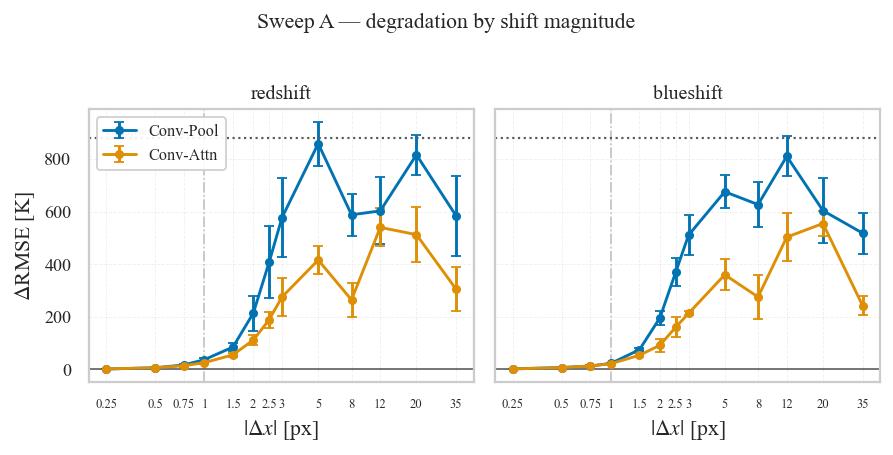

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.4), sharey=True)

for ax, direction in zip(axes, DIRECTIONS):
    for m in MODELS:
        g = ov_A[(ov_A.model == m) &
                 (ov_A.direction == direction)].groupby('dx_mag')['d_rmse_K']
        ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                    color=COLORS[m], marker='o', ms=4, lw=1.6, capsize=3, label=m)
    ax.axhline(0, color='0.35', lw=0.9)
    ax.axhline(CEILING_MEAN, color='0.35', ls=':', lw=1.2)
    ax.axvline(1.0, color='0.75', lw=0.9, ls='-.', zorder=0)
    ax.set_xscale('log')
    ax.set_xticks(DX_LEVELS)
    ax.set_xticklabels([f'{d:g}' for d in DX_LEVELS], fontsize=7)
    ax.set_xlabel(r'$|\Delta x|$ [px]')
    ax.set_title(direction, fontsize=11)
    ax.grid(True, ls='--', alpha=0.3, lw=0.5)

axes[0].text(DX_LEVELS[0], CEILING_MEAN, 'collapse ceiling', fontsize=7,
             va='bottom', ha='left', color='0.35')
axes[0].set_ylabel(r'$\Delta$RMSE [K]')
axes[0].legend(fontsize=9, framealpha=0.92, loc='upper left')
fig.suptitle('Sweep A — degradation by shift magnitude', y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

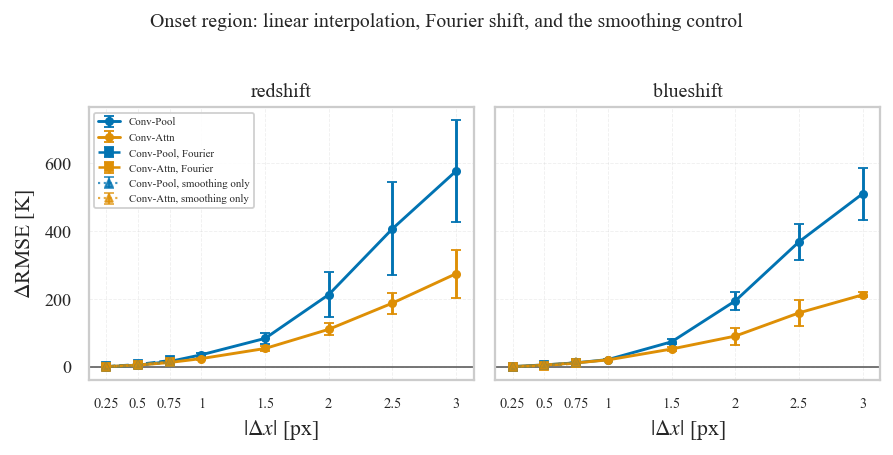

In [25]:
sub_lo = [d for d in DX_LEVELS if d <= 3]
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.4), sharey=True)

for ax, direction in zip(axes, DIRECTIONS):
    for m in MODELS:
        g = (ov_A[(ov_A.model == m) & (ov_A.direction == direction) &
                  (ov_A.dx_mag <= 3)].groupby('dx_mag')['d_rmse_K'])
        ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                    color=COLORS[m], marker='o', ms=4, lw=1.6, capsize=3, label=m)
    for m in MODELS:
        g = (ov_D[(ov_D.model == m) &
                  (ov_D.direction == direction)].groupby('dx_mag')['d_rmse_K'])
        ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                    color=COLORS[m], marker='s', ms=4, lw=1.4, ls='--', capsize=3,
                    label=f'{m}, Fourier')
    for m in MODELS:
        g = ov_s[ov_s.model == m].groupby('f')['d_rmse_K']
        ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                    color=COLORS[m], marker='^', ms=4, lw=1.2, ls=':', capsize=3,
                    alpha=0.75, label=f'{m}, smoothing only')
    ax.axhline(0, color='0.35', lw=0.9)
    ax.set_xticks(sub_lo)
    ax.set_xticklabels([f'{d:g}' for d in sub_lo], fontsize=8)
    ax.set_xlabel(r'$|\Delta x|$ [px]')
    ax.set_title(direction, fontsize=11)
    ax.grid(True, ls='--', alpha=0.3, lw=0.5)

axes[0].set_ylabel(r'$\Delta$RMSE [K]')
axes[0].legend(fontsize=6, framealpha=0.92, loc='upper left', ncol=1)
fig.suptitle('Onset region: linear interpolation, Fourier shift, and the smoothing '
             'control', y=1.02, fontsize=11)
plt.tight_layout()
plt.show()

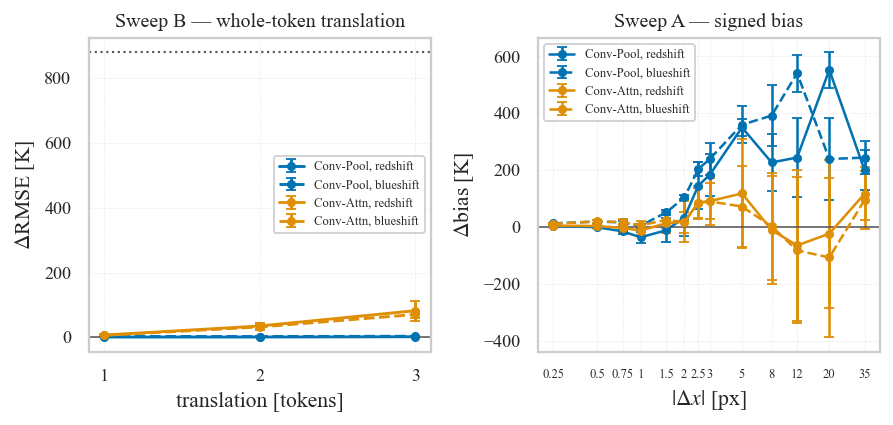

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.4))

for m in MODELS:
    for direction in DIRECTIONS:
        g = ov_B[(ov_B.model == m) &
                 (ov_B.direction == direction)].groupby('dx_mag')['d_rmse_K']
        axes[0].errorbar([x / STEM_DOWNSAMPLE for x in g.mean().index],
                         g.mean().values, yerr=g.std().values,
                         color=COLORS[m], ls=DIR_STYLE[direction], marker='o', ms=4,
                         lw=1.6, capsize=3, label=f'{m}, {direction}')
axes[0].axhline(0, color='0.35', lw=0.9)
axes[0].axhline(CEILING_MEAN, color='0.35', ls=':', lw=1.2)
axes[0].set_xticks([t // STEM_DOWNSAMPLE for t in TOKEN_LEVELS])
axes[0].set_xlabel('translation [tokens]')
axes[0].set_ylabel(r'$\Delta$RMSE [K]')
axes[0].set_title('Sweep B — whole-token translation', fontsize=11)
axes[0].legend(fontsize=7, framealpha=0.92)
axes[0].grid(True, ls='--', alpha=0.3, lw=0.5)

for m in MODELS:
    for direction in DIRECTIONS:
        g = ov_A[(ov_A.model == m) &
                 (ov_A.direction == direction)].groupby('dx_mag')['d_bias_K']
        axes[1].errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                         color=COLORS[m], ls=DIR_STYLE[direction], marker='o', ms=4,
                         lw=1.4, capsize=3, label=f'{m}, {direction}')
axes[1].axhline(0, color='0.35', lw=0.9)
axes[1].set_xscale('log')
axes[1].set_xticks(DX_LEVELS)
axes[1].set_xticklabels([f'{d:g}' for d in DX_LEVELS], fontsize=7)
axes[1].set_xlabel(r'$|\Delta x|$ [px]')
axes[1].set_ylabel(r'$\Delta$bias [K]')
axes[1].set_title('Sweep A — signed bias', fontsize=11)
axes[1].legend(fontsize=7, framealpha=0.92)
axes[1].grid(True, ls='--', alpha=0.3, lw=0.5)

plt.tight_layout()
plt.show()

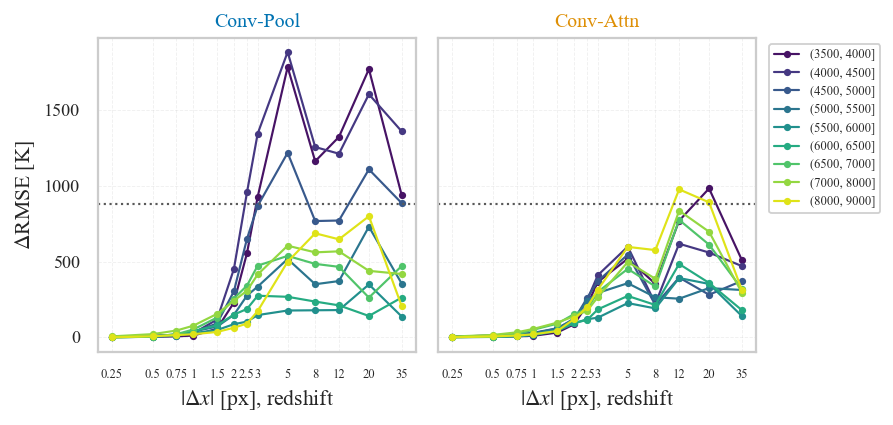

In [27]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(W_DOUBLE, 3.4), sharey=True)
cmap = plt.get_cmap('viridis')
colors_reg = cmap(np.linspace(0.05, 0.95, len(REG_LABELS)))

sub = deg[(deg.sweep == 'A') & (deg.direction == 'redshift') & (deg.regime != 'all')]
for ax, m in zip(axes, MODELS):
    for lab, cl in zip(REG_LABELS, colors_reg):
        g = sub[(sub.model == m) & (sub.regime == lab)].groupby('dx_mag')['d_rmse_K'].mean()
        ax.plot(g.index, g.values, marker='o', ms=3, lw=1.2, color=cl, label=lab)
    ax.axhline(CEILING_MEAN, color='0.35', ls=':', lw=1.2)
    ax.set_xscale('log')
    ax.set_xticks(DX_LEVELS)
    ax.set_xticklabels([f'{d:g}' for d in DX_LEVELS], fontsize=7)
    ax.set_xlabel(r'$|\Delta x|$ [px], redshift')
    ax.set_title(m, color=COLORS[m], fontsize=11)
    ax.grid(True, ls='--', alpha=0.3, lw=0.5)

axes[0].set_ylabel(r'$\Delta$RMSE [K]')
axes[-1].legend(fontsize=7, ncol=1, framealpha=0.92, loc='upper left',
                bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.show()

## 5.3.11 Export

All dictionaries below are built with explicit loops rather than comprehensions containing `DataFrame.query`, and the exported summary is checked against the tables above.

In [28]:
def level_summary(df, keys, key_names, value='d_rmse_K'):
    out = {}
    for m in MODELS:
        per = {}
        for k in keys:
            sel = df['model'] == m
            for name, val in zip(key_names, k if isinstance(k, tuple) else (k,)):
                sel = sel & (df[name] == val)
            v = df[sel][value]
            per['|'.join(str(x) for x in (k if isinstance(k, tuple) else (k,)))] = \
                [float(v.mean()), float(v.std())]
        out[m] = per
    return out


keys_A = []
for d in DIRECTIONS:
    for mag in DX_LEVELS:
        keys_A.append((d, float(mag)))
keys_B = []
for d in DIRECTIONS:
    for mag in TOKEN_LEVELS:
        keys_B.append((d, float(mag)))
keys_C = [float(f_) for f_ in SMOOTH_LEVELS]
keys_D = []
for d in DIRECTIONS:
    for mag in FOURIER_LEVELS:
        keys_D.append((d, float(mag)))

meta = {
    'step': '5.3',
    'attack': ATTACK,
    'description': 'uniform pixel displacement with edge replication, run separately '
                   'in each direction, with a whole-token sweep and a smoothing control',
    'attack_seed': ATTACK_SEED,
    'n_test': int(N_TEST),
    'seeds': SEEDS,
    'models': MODELS,
    'eval_batch_size': BATCH_SIZE,
    'catastrophic_threshold_K': CATASTROPHIC_K,
    'collapse_rmse_K': COLLAPSE_RMSE,
    'collapse_ceiling_d_rmse_K': CEILING,
    'stem_downsample': STEM_DOWNSAMPLE,
    'directions': DIRECTIONS,
    'direction_sign': DIR_SIGN,
    'edge_fill': 'boundary value replicated into the vacated pixels, matching the '
                 'Step 2 blue-edge convention',
    'interpolation': 'linear, two-tap [1-f, f]; Nyquist response |1-2f|',
    'sweep_A': {
        'levels_px': [float(d) for d in DX_LEVELS],
        'levels_km_s': [round(d * KMS_PER_PIXEL, 1) for d in DX_LEVELS],
        'd_rmse_K': level_summary(ov_A, keys_A, ['direction', 'dx_mag']),
        'd_bias_K': level_summary(ov_A, keys_A, ['direction', 'dx_mag'],
                                  value='d_bias_K')},
    'sweep_B': {
        'levels_px': [float(t) for t in TOKEN_LEVELS],
        'levels_tokens': [t // STEM_DOWNSAMPLE for t in TOKEN_LEVELS],
        'd_rmse_K': level_summary(ov_B, keys_B, ['direction', 'dx_mag']),
        'd_bias_K': level_summary(ov_B, keys_B, ['direction', 'dx_mag'],
                                  value='d_bias_K')},
    'sweep_C': {
        'levels_f': keys_C,
        'nyquist_response': [round(1 - 2 * f_, 3) for f_ in SMOOTH_LEVELS],
        'd_rmse_K': level_summary(ov_s, keys_C, ['f'])},
    'sweep_D': {
        'method': 'Fourier phase ramp, edge-replicated padding of '
                  f'{FOURIER_PAD} px, Nyquist bin zeroed',
        'levels_px': [float(l) for l in FOURIER_LEVELS],
        'd_rmse_K': level_summary(ov_D, keys_D, ['direction', 'dx_mag']),
        'd_bias_K': level_summary(ov_D, keys_D, ['direction', 'dx_mag'],
                                  value='d_bias_K'),
        'null_control_d_rmse_K': {
            m: [float(ov_D0[ov_D0.model == m]['d_rmse_K'].mean()),
                float(ov_D0[ov_D0.model == m]['d_rmse_K'].std())] for m in MODELS}},
    'grid': GRID,
}
with open(os.path.join(RESULTS_DIR, 'step53_meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)

print('Written to results/:')
for fn in sorted(f for f in os.listdir(RESULTS_DIR) if f.startswith('step53')):
    p = os.path.join(RESULTS_DIR, fn)
    if os.path.isfile(p):
        print(f'  {fn:42s} {os.path.getsize(p) / 1024:7.1f} KB')
tot = sum(os.path.getsize(os.path.join(STEP53_DIR, f))
          for f in os.listdir(STEP53_DIR)) / 1024 ** 2
print(f'  step53/  (per-spectrum predictions, every configuration)  {tot:.1f} MB')

# the exported summary must agree with the tables above
for m in MODELS:
    for d in DIRECTIONS:
        key = f'{d}|{float(DX_LEVELS[-1])}'
        a = meta['sweep_A']['d_rmse_K'][m][key][0]
        b = float(ov_A[(ov_A.direction == d) & (ov_A.dx_mag == float(DX_LEVELS[-1])) &
                       (ov_A.model == m)]['d_rmse_K'].mean())
        assert abs(a - b) < 1e-9, f'sweep A summary disagrees with the table, {m}, {d}'
        key = f'{d}|{float(TOKEN_LEVELS[-1])}'
        a = meta['sweep_B']['d_rmse_K'][m][key][0]
        b = float(ov_B[(ov_B.direction == d) & (ov_B.dx_mag == float(TOKEN_LEVELS[-1])) &
                       (ov_B.model == m)]['d_rmse_K'].mean())
        assert abs(a - b) < 1e-9, f'sweep B summary disagrees with the table, {m}, {d}'
for m in MODELS:
    for d in DIRECTIONS:
        key = f'{d}|{float(FOURIER_LEVELS[-1])}'
        a = meta['sweep_D']['d_rmse_K'][m][key][0]
        b = float(ov_D[(ov_D.direction == d) &
                       (ov_D.dx_mag == float(FOURIER_LEVELS[-1])) &
                       (ov_D.model == m)]['d_rmse_K'].mean())
        assert abs(a - b) < 1e-9, f'sweep D summary disagrees with the table, {m}, {d}'
print()
print('Exported summaries verified against the in-notebook tables.')

Written to results/:
  step53_asymmetry_tests.csv                     3.0 KB
  step53_asymmetry_tests_bias.csv                3.6 KB
  step53_degradation.csv                      1101.5 KB
  step53_degradation_fourier.csv               208.8 KB
  step53_degradation_fourier_null.csv           34.3 KB
  step53_degradation_smoothing.csv             100.1 KB
  step53_fourier_comparison.csv                  2.0 KB
  step53_meta.json                              18.2 KB
  step53_overshoot.csv                           0.4 KB
  step53_paired_tests.csv                        3.0 KB
  step53_phase_decomposition.csv                 1.3 KB
  step53_smoothing_control.csv                   0.9 KB
  step53/  (per-spectrum predictions, every configuration)  26.0 MB

Exported summaries verified against the in-notebook tables.
